# А-14-23 Кузнецов Давид
# Лабораторная работа № 3. Вариант В

## Задача 1

Для реализаций $k$ независимых выборок $\xi^{(j)}$ из нормальных распределений $\mathcal{N}(a_j, \sigma^2)$ объёмами $n_j$ требуется проверить основную гипотезу
$$H_0: a_1 = \dots = a_k$$
против альтернативной гипотезы $H_1$, согласно которой равны не все математические ожидания.

Статистика критерия вычисляется по формулам:
$$
m_j = \sum_{i=1}^{n_j} \xi_i^{(j)}, \qquad
s_j^2 = \sum_{i=1}^{n_j} \left(\xi_i^{(j)}\right)^2, \qquad
n = \sum_{j=1}^k n_j,
$$
$$
m^2 = \sum_{j=1}^k \frac{m_j^2}{n_j}, \qquad
n\widetilde{s}^2 = m^2 - \frac{1}{n}\left(\sum_{j=1}^k m_j\right)^2,
$$
$$
n\widehat{s}^2 = \sum_{j=1}^k s_j^2-m^2, \qquad
T = \frac{n\widetilde{s}^2/(k-1)}{n\widehat{s}^2/(n-k)}.
$$
При справедливости $H_0$ статистика имеет распределение Фишера $F(k-1,n-k)$. Минимальный уровень значимости, при котором гипотеза отклоняется, равен
$$p = 1-F_F(T;k-1,n-k).$$

где $F_F(x; k-1, n-k)$ - функция распределения для распределения Фишера с числом степеней свободы $k-1$ и $n-k$.

Для каждого примера в одной системе координат изобразите точками компоненты реализаций выборок, откладывая по оси абсцисс номер и значения по оси ординат.

В работе дополнительно используется стандартный уровень значимости $\alpha_0=0{,}05$: если $p<\alpha_0$, гипотеза $H_0$ отклоняется.

1.
- $\xi^{(1)}$ - выборка из нормального распределения $\mathcal{N}(1,0.25)$ объёма $n_1 = 35$,
- $\xi^{(2)}$ - выборка из нормального распределения $\mathcal{N}(1,0.25)$ объёма $n_2 = 30$,
- $\xi^{(3)}$ - выборка из нормального распределения $\mathcal{N}(1,0.25)$ объёма $n_1 = 45$.


2.
- $\xi^{(1)}$ - выборка из нормального распределения $\mathcal{N}(1,0.25)$ объёма $n_1 = 40$,
- $\xi^{(2)}$ - выборка из нормального распределения $\mathcal{N}(2.5,0.25)$ объёма $n_2 = 55$,
- $\xi^{(3)}$ - выборка из нормального распределения $\mathcal{N}(-1,0.25)$ объёма $n_3 = 50$.

3.
- $\xi^{(1)}$ - выборка из нормального распределения $\mathcal{N}(2,2)$ объёма $n_1 = 30$,
- $\xi^{(2)}$ - выборка из нормального распределения $\mathcal{N}(2.3,2)$ объёма $n_2 = 25$,
- $\xi^{(3)}$ - выборка из нормального распределения $\mathcal{N}(1.8,2)$ объёма $n_3 = 40$,
- $\xi^{(4)}$ - выборка из нормального распределения $\mathcal{N}(1.95,2)$ объёма $n_4 = 35$.

## Программная реализация

Для воспроизводимости каждому примеру назначено фиксированное начальное значение генератора случайных чисел. В параметризации $\mathcal{N}(a,\sigma^2)$ второе число является **дисперсией**, поэтому в `numpy` передаётся стандартное отклонение $\sigma=\sqrt{\sigma^2}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import f

plt.style.use("seaborn-v0_8-whitegrid")
ALPHA_0 = 0.05    #стандартный уровень значимости 


def calculate_anova(samples):
    """Вычисляет статистику T"""
    arrays = [np.asarray(sample, dtype=float) for sample in samples]   #выборка преобразуется в массив
    if len(arrays) < 2:
        raise ValueError("Необходимо не менее двух выборок.")
    if any(len(sample) < 2 for sample in arrays):
        raise ValueError("В каждой выборке должно быть не менее двух наблюдений.")
    if any(not np.isfinite(sample).all() for sample in arrays):
        raise ValueError("Все наблюдения должны быть конечными числами.")

    k = len(arrays)
    n_j = np.array([len(sample) for sample in arrays], dtype=int)   #объем выборки 
    n = int(n_j.sum()) 

    # m_j — сумма элементов j-й выборки; s_j^2 — сумма их квадратов.
    m_j = np.array([sample.sum() for sample in arrays])
    s_j_squared = np.array([np.dot(sample, sample) for sample in arrays])

    m_squared = np.sum(m_j**2 / n_j)
    n_s_tilde_squared = m_squared - m_j.sum()**2 / n      # межгрупповая сумма квадратов
    n_s_hat_squared = s_j_squared.sum() - m_squared       # внутригрупповая сумма квадратов

    if n_s_hat_squared <= 0:
        raise ValueError("Внутригрупповая сумма квадратов должна быть положительной.")

    df_between = k - 1
    df_within = n - k
    t_value = (n_s_tilde_squared / df_between) / (n_s_hat_squared / df_within)    # T 
    # survival function точнее прямого вычисления 1 - cdf при очень малых p.
    p_value = f.sf(t_value, df_between, df_within)

    return {
        "k": k, "n": n, "n_j": n_j, "m_j": m_j,
        "s_j_squared": s_j_squared, "m_squared": m_squared,
        "n_s_tilde_squared": n_s_tilde_squared,
        "n_s_hat_squared": n_s_hat_squared,
        "df_between": df_between, "df_within": df_within,
        "T": t_value, "p_value": p_value,
    }


def solve_example(number, specifications, seed):
    """Генерирует выборки, выводит расчёты, решение и общий график"""
    rng = np.random.default_rng(seed)
    samples = [
        rng.normal(loc=mean, scale=np.sqrt(variance), size=size)
        for mean, variance, size in specifications
    ]
    result = calculate_anova(samples)

    rows = []
    for j, (sample, (mean, variance, size)) in enumerate(zip(samples, specifications), start=1):
        rows.append({
            "Выборка": f"ξ^({j})", "a_j": mean, "σ²": variance, "n_j": size,
            "Выборочное среднее": sample.mean(),
            "m_j": result["m_j"][j - 1],
            "s_j²": result["s_j_squared"][j - 1],
        })

    print(f"ПРИМЕР {number}")
    print(pd.DataFrame(rows).round(6).to_string(index=False))
    print(f"k = {result['k']}, n = {result['n']}")
    print(f"m² = {result['m_squared']:.6f}")
    print(f"n·s̃² (межгрупповая сумма квадратов) = {result['n_s_tilde_squared']:.6f}")
    print(f"n·ŝ² (внутригрупповая сумма квадратов) = {result['n_s_hat_squared']:.6f}")
    print(f"T = {result['T']:.6f}")
    print(f"Минимальный уровень значимости (p-value) = {result['p_value']:.10g}")

    rejected = result["p_value"] < ALPHA_0
    decision = "H₀ отклоняется" if rejected else "нет оснований отклонять H₀"
    print(f"При α₀ = {ALPHA_0}: {decision}.")

    fig, ax = plt.subplots(figsize=(10, 5))
    for j, sample in enumerate(samples, start=1):
        ax.scatter(np.arange(1, len(sample) + 1), sample, s=30, alpha=0.75,
                   label=f"ξ^({j}), среднее={sample.mean():.3f}")
    overall_mean = np.concatenate(samples).mean()
    ax.axhline(overall_mean, color="black", linestyle="--", linewidth=1.3,
               label=f"общее среднее={overall_mean:.3f}")
    ax.set_title(f"Пример {number}: реализации выборок")
    ax.set_xlabel("Номер наблюдения внутри выборки")
    ax.set_ylabel("Значение наблюдения")
    ax.legend(ncol=2)
    plt.tight_layout()
    plt.show()

    return {"Пример": number, "T": result["T"],
            "p-value": result["p_value"],
            "Решение при α=0.05": decision}


## Пример 1

- $\xi^{(1)}$ — выборка из $\mathcal{N}(1;0{,}25)$ объёма $n_1=35$;
- $\xi^{(2)}$ — выборка из $\mathcal{N}(1;0{,}25)$ объёма $n_2=30$;
- $\xi^{(3)}$ — выборка из $\mathcal{N}(1;0{,}25)$ объёма $n_3=45$.

Теоретические математические ожидания совпадают, поэтому ожидается, что полученная реализация не будет противоречить $H_0$.

ПРИМЕР 1
Выборка  a_j   σ²  n_j  Выборочное среднее       m_j      s_j²
  ξ^(1)  1.0 0.25   35            1.124180 39.346317 52.889725
  ξ^(2)  1.0 0.25   30            1.119656 33.589669 47.547182
  ξ^(3)  1.0 0.25   45            1.065914 47.966120 61.805878
k = 3, n = 110
m² = 132.968971
n·s̃² (межгрупповая сумма квадратов) = 0.084252
n·ŝ² (внутригрупповая сумма квадратов) = 29.273814
T = 0.153976
Минимальный уровень значимости (p-value) = 0.8574820886
При α₀ = 0.05: нет оснований отклонять H₀.


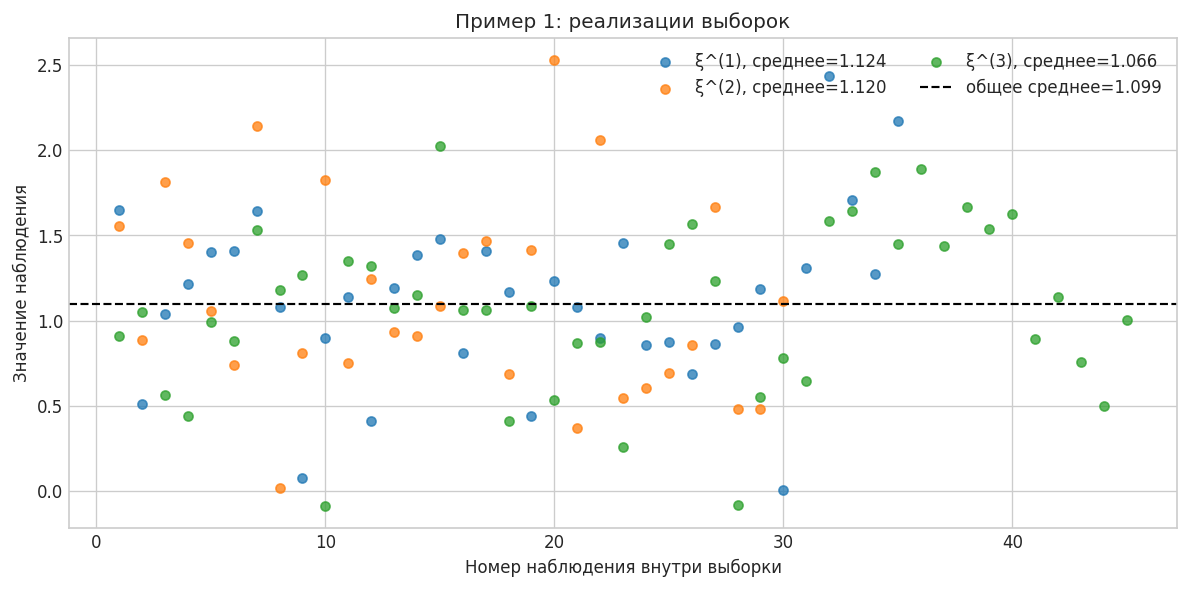

In [2]:
specifications_1 = [(1.0, 0.25, 35), (1.0, 0.25, 30), (1.0, 0.25, 45)]
result_1 = solve_example(1, specifications_1, seed=20261)

## Пример 2

- $\xi^{(1)}$ — выборка из $\mathcal{N}(1;0{,}25)$ объёма $n_1=40$;
- $\xi^{(2)}$ — выборка из $\mathcal{N}(2{,}5;0{,}25)$ объёма $n_2=55$;
- $\xi^{(3)}$ — выборка из $\mathcal{N}(-1;0{,}25)$ объёма $n_3=50$.

Математические ожидания существенно различаются, поэтому ожидается отклонение $H_0$.

ПРИМЕР 2
Выборка  a_j   σ²  n_j  Выборочное среднее        m_j       s_j²
  ξ^(1)  1.0 0.25   40            1.037111  41.484421  51.472064
  ξ^(2)  2.5 0.25   55            2.452558 134.890682 346.430930
  ξ^(3) -1.0 0.25   50           -1.012350 -50.617480  64.456927
k = 3, n = 145
m² = 425.093715
n·s̃² (межгрупповая сумма квадратов) = 316.024889
n·ŝ² (внутригрупповая сумма квадратов) = 37.266207
T = 602.094206
Минимальный уровень значимости (p-value) = 4.425448167e-70
При α₀ = 0.05: H₀ отклоняется.


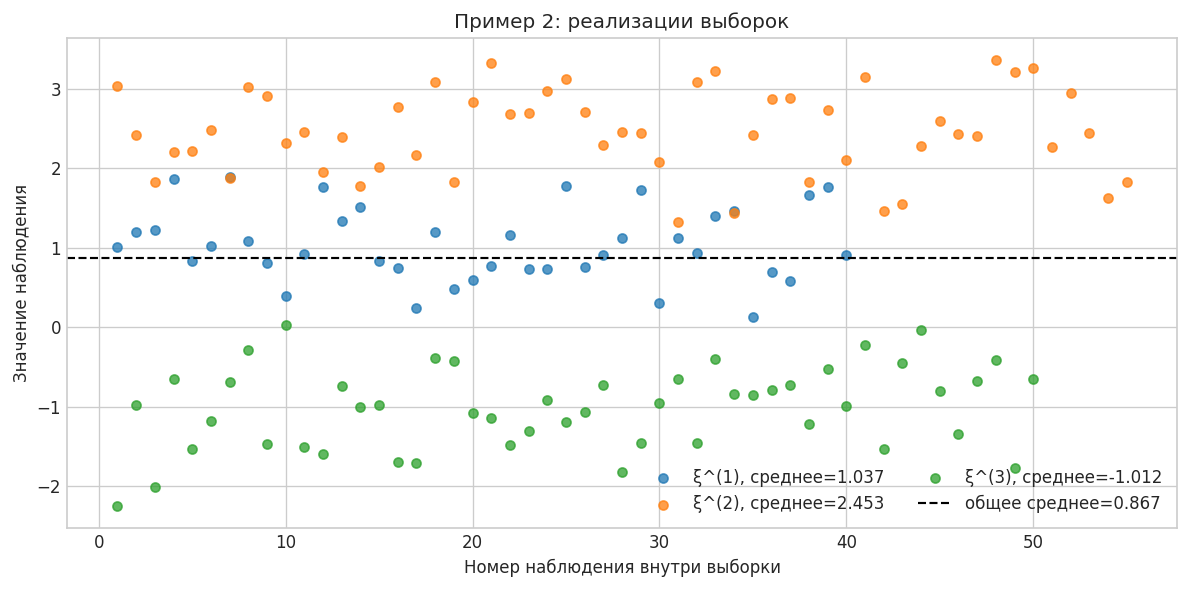

In [3]:
specifications_2 = [(1.0, 0.25, 40), (2.5, 0.25, 55), (-1.0, 0.25, 50)]
result_2 = solve_example(2, specifications_2, seed=20262)

## Пример 3

- $\xi^{(1)}$ — выборка из $\mathcal{N}(2;2)$ объёма $n_1=30$;
- $\xi^{(2)}$ — выборка из $\mathcal{N}(2{,}3;2)$ объёма $n_2=25$;
- $\xi^{(3)}$ — выборка из $\mathcal{N}(1{,}8;2)$ объёма $n_3=40$;
- $\xi^{(4)}$ — выборка из $\mathcal{N}(1{,}95;2)$ объёма $n_4=35$.

Различия между математическими ожиданиями невелики по сравнению с дисперсией $\sigma^2=2$, поэтому результат критерия зависит от отношения межгруппового и внутригруппового разбросов.

ПРИМЕР 3
Выборка  a_j  σ²  n_j  Выборочное среднее       m_j       s_j²
  ξ^(1) 2.00 2.0   30            1.915962 57.478868 174.947635
  ξ^(2) 2.30 2.0   25            2.185031 54.625783 163.502287
  ξ^(3) 1.80 2.0   40            1.887578 75.503130 220.074639
  ξ^(4) 1.95 2.0   35            2.091470 73.201450 214.417426
k = 4, n = 130
m² = 525.103093
n·s̃² (межгрупповая сумма квадратов) = 1.861130
n·ŝ² (внутригрупповая сумма квадратов) = 247.838894
T = 0.315396
Минимальный уровень значимости (p-value) = 0.814223238
При α₀ = 0.05: нет оснований отклонять H₀.


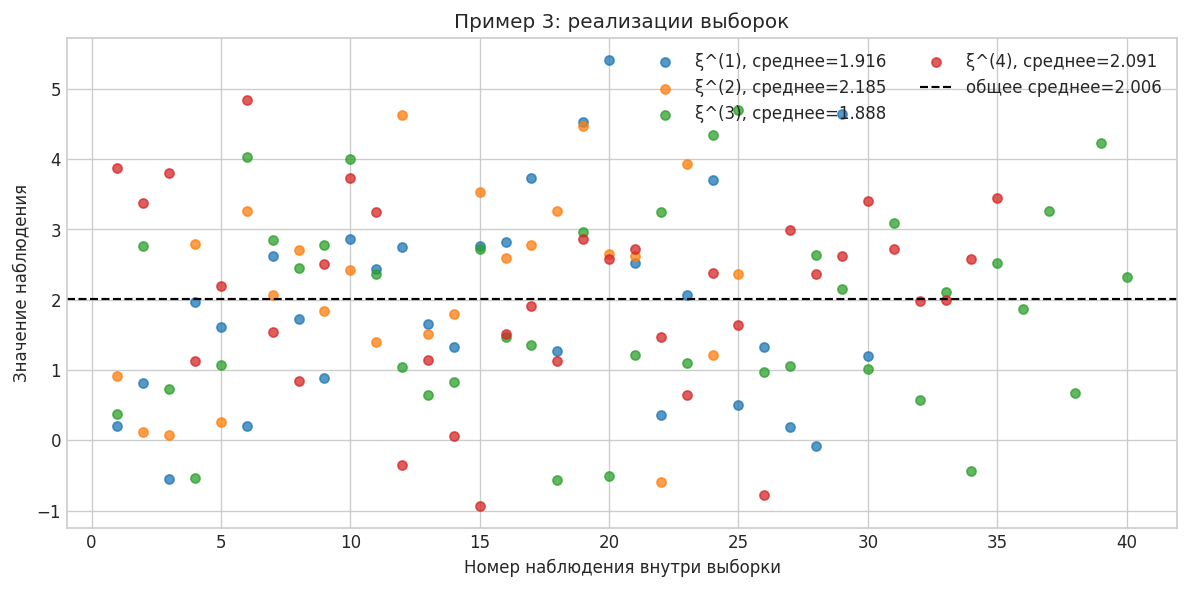

In [4]:
specifications_3 = [(2.0, 2.0, 30), (2.3, 2.0, 25), (1.8, 2.0, 40), (1.95, 2.0, 35)]
result_3 = solve_example(3, specifications_3, seed=20263)

## Итоговые результаты

In [5]:
summary = pd.DataFrame([result_1, result_2, result_3])
print(summary.to_string(index=False))

print("Вывод:")
print("1. В примере 1 полученные данные не противоречат гипотезе H₀.")
print("2. В примере 2 межгрупповой разброс значительно превышает внутригрупповой; H₀ уверенно отклоняется.")
print("3. В примере 3 различия средних малы относительно дисперсии; для реализации нет оснований отклонять H₀ на уровне 0.05.")
print("Однофакторный дисперсионный анализ выявил существенное влияние фактора только во втором примере.")

 Пример          T      p-value         Решение при α=0.05
      1   0.153976 8.574821e-01 нет оснований отклонять H₀
      2 602.094206 4.425448e-70             H₀ отклоняется
      3   0.315396 8.142232e-01 нет оснований отклонять H₀
Вывод:
1. В примере 1 полученные данные не противоречат гипотезе H₀.
2. В примере 2 межгрупповой разброс значительно превышает внутригрупповой; H₀ уверенно отклоняется.
3. В примере 3 различия средних малы относительно дисперсии; для реализации нет оснований отклонять H₀ на уровне 0.05.
Однофакторный дисперсионный анализ выявил существенное влияние фактора только во втором примере.
